# Step 4: Robustness tests 
**Needs (same folder):** `data_prep.py`, `features_v3.py`, `transfer_v3.py`, the v3 feature files, and `clean/clean_amsterdam.parquet`.

Two questions a judge will ask, answered with the FROZEN method (Random Forest + blend3 + smoothing). Nothing here changes the submission.

* **Test A, reverse direction:** train on Amsterdam, adapt to Madrid with n labels. If the method only worked because of something special about Madrid to Amsterdam, it would fall apart here.
* **Test B, different conditions:** make Amsterdam darker, brighter, noisier, or cloudier (fewer clear years), rebuild the features, and rerun the transfer. Also compares our "own scaling" (city calibration) with Madrid scaling under each condition.

Leakage rules still hold: target labels are only used for the n support pixels; the rest are only used to score. The perturbations touch only satellite values, never labels.

Outputs: `results/reverse_direction.csv`, `results/reverse_vs_forward.png`, `results/stress_test.csv`.
Run time: Test A about 20 to 30 min, Test B about 30 to 45 min (16 cores). The time per step is printed so you can see progress.

In [1]:
import time, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

import data_prep as dp, features_v3 as fv3, transfer_v3 as tv3
for m in (dp, fv3, tv3):
    importlib.reload(m)                        # always use the latest uploaded version
assert hasattr(tv3, "smooth_proba"), "old transfer_v3.py loaded: upload the latest one"

SEED    = tv3.SEED                             # 42, same as everything else
CLASSES = tv3.CLASSES
SHOTS   = (5, 25, 50, 100, 200)                # all five n for the reverse test (same as the brief)
TRIALS  = 10                                   # same 10 seeds (42..51) as the official run
STRESS_SHOTS  = (5, 25, 200)                   # stress test: low, prize n=25, peak (saves time)
STRESS_TRIALS = 5
CLEAN = Path("clean")
OUT = Path("results"); OUT.mkdir(exist_ok=True)


def run_blend3(data, stage1, n, seed):
    """One blend3 transfer run. Returns (F1 raw, F1 with 3x3 smoothing).
    Uses the exact frozen code path (tv3.adapt_to_amsterdam), then re-predicts the query pixels with the
    saved model so we can smooth them. Smoothing only mixes predicted probabilities of QUERY pixels
    (support pixels are left out as neighbours), same as the official validation."""
    f1_raw, model = tv3.adapt_to_amsterdam(data, stage1, n, seed, "blend3")
    y = data["ya"]
    qry = np.setdiff1d(np.arange(len(y)), model["support_index"])
    P = tv3.predict_proba_blend3(model, stage1, data["Xa"][qry])
    # safety check: re-predicting must give exactly the same score as the frozen function
    f1_check = f1_score(y[qry], CLASSES[P.argmax(1)], average="macro")
    assert abs(f1_check - f1_raw) < 1e-9, "re-prediction does not match, something is out of sync"
    Ps = tv3.smooth_proba(P, data["ids_a"][qry], alpha=0.5, r=1)
    return f1_raw, f1_score(y[qry], CLASSES[Ps.argmax(1)], average="macro")


def in_city_cv(X, y):
    """Ceiling: Random Forest trained and tested inside ONE city (5-fold, random). The best a model can
    do when it has all the labels of that city. Transfer is judged by how close it gets to this."""
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    s = [f1_score(y[va], RandomForestClassifier(**tv3.RF_PARAMS).fit(X[tr], y[tr]).predict(X[va]),
                  average="macro") for tr, va in skf.split(X, y)]
    return np.mean(s), np.std(s)

print("setup OK, tv3.SCALING =", tv3.SCALING)

setup OK, tv3.SCALING = own


## Test A: reverse direction (Amsterdam -> Madrid)
We simply swap the two cities in the data dictionary. The transfer code itself is untouched, so "Amsterdam" inside `transfer_v3.py` now means "the target city", which is Madrid here.
* Stage 1 = Random Forest on ALL Amsterdam pixels.
* Own scaling = Madrid features scaled on Madrid's own statistics (no labels), the mirror image of the forward run.
* Madrid in-city CV is the ceiling for this direction; Amsterdam in-city CV is the ceiling for the forward direction.

In [2]:
t0 = time.time()
fwd = tv3.load_data(".")                                           # forward data, as in the official run
mad = pd.read_parquet("features_madrid_v3.parquet")
ids_m = mad[["px_key", "py_key"]].to_numpy()
assert (mad["age_class"].to_numpy(int) == fwd["ym"]).all()        # same pixel order as load_data

rev = {"cols": fwd["cols"],
       "Xm": fwd["Xa"], "ym": fwd["ya"],                          # SOURCE (training city) = Amsterdam
       "Xa": fwd["Xm"], "ya": fwd["ym"],                          # TARGET city = Madrid
       "ids_a": ids_m}
print(f"source Amsterdam {len(rev['ym'])} pixels, target Madrid {len(rev['ya'])} pixels")

# Ceilings (all labels, inside one city)
ceil_mad = in_city_cv(fwd["Xm"], fwd["ym"])
ceil_ams = in_city_cv(fwd["Xa"], fwd["ya"])
print(f"in-city CV  Madrid {ceil_mad[0]:.3f} +/- {ceil_mad[1]:.3f} | Amsterdam {ceil_ams[0]:.3f} +/- {ceil_ams[1]:.3f}"
      f"  ({time.time()-t0:.0f}s)")

stage1_rev = tv3.train_stage1(rev)                                 # RF on Amsterdam, Madrid scaled on itself
zero_rev = f1_score(rev["ya"], stage1_rev["rf"].predict(rev["Xa"]), average="macro")
print(f"zero-shot Amsterdam model on Madrid: {zero_rev:.3f}")

rows = []
for n in SHOTS:
    t = time.time()
    res = np.array([run_blend3(rev, stage1_rev, n, SEED + k) for k in range(TRIALS)])
    rows.append({"direction": "Amsterdam->Madrid", "n_per_class": n,
                 "f1_mean": res[:, 0].mean(), "f1_std": res[:, 0].std(),
                 "f1_smooth_mean": res[:, 1].mean(), "f1_smooth_std": res[:, 1].std(),
                 "smooth_wins": int((res[:, 1] > res[:, 0]).sum())})
    r = rows[-1]
    print(f"n={n:3d}  blend3 {r['f1_mean']:.3f} +/- {r['f1_std']:.3f} | smoothed {r['f1_smooth_mean']:.3f}"
          f"  (smoothing better in {r['smooth_wins']}/{TRIALS})  {time.time()-t:.0f}s")

reverse = pd.DataFrame(rows)
reverse["zero_shot"] = zero_rev
reverse["ceiling_in_city"] = ceil_mad[0]
reverse.round(4).to_csv(OUT / "reverse_direction.csv", index=False)
print(f"saved results/reverse_direction.csv  (total {time.time()-t0:.0f}s)")

source Amsterdam 25992 pixels, target Madrid 76263 pixels
in-city CV  Madrid 0.657 +/- 0.005 | Amsterdam 0.775 +/- 0.004  (106s)
zero-shot Amsterdam model on Madrid: 0.336
n=  5  blend3 0.423 +/- 0.027 | smoothed 0.433  (smoothing better in 10/10)  52s
n= 25  blend3 0.512 +/- 0.014 | smoothed 0.525  (smoothing better in 10/10)  52s
n= 50  blend3 0.518 +/- 0.012 | smoothed 0.532  (smoothing better in 10/10)  53s
n=100  blend3 0.540 +/- 0.007 | smoothed 0.557  (smoothing better in 10/10)  53s
n=200  blend3 0.555 +/- 0.005 | smoothed 0.569  (smoothing better in 10/10)  54s
saved results/reverse_direction.csv  (total 378s)


### Forward vs reverse, side by side
Forward numbers are the official run (PROJECT_LOG section 7d, results/results_table.csv). The fair way to compare two directions is **how much of the in-city ceiling the transfer recovers**, because Madrid and Amsterdam are not equally hard.

ceilings: Amsterdam 0.775, Madrid 0.657 | zero-shot fwd 0.453, rev 0.336
average of 5 n: forward 0.655, reverse 0.510 (smoothed 0.523)


,n_per_class,forward_f1 (Mad->Ams),forward_%_of_ceiling,reverse_f1 (Ams->Mad),reverse_%_of_ceiling
0,5,0.580,74.817,0.423,64.500
1,25,0.641,82.686,0.512,78.017
2,50,0.666,85.911,0.518,78.854
3,100,0.683,88.104,0.540,82.196
4,200,0.703,90.684,0.555,84.567


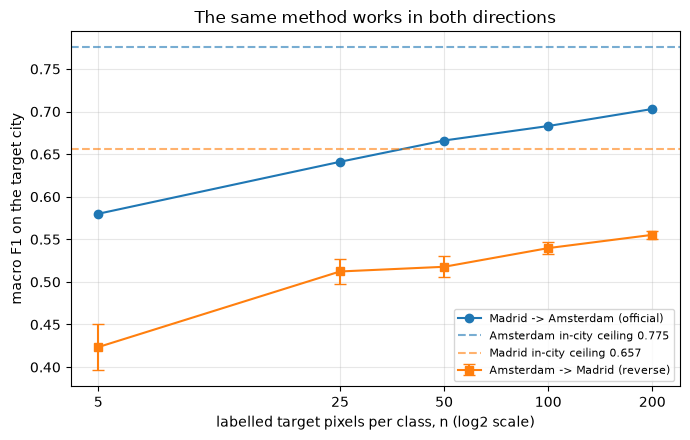

In [3]:
FORWARD = {5: 0.580, 25: 0.641, 50: 0.666, 100: 0.683, 200: 0.703}   # official blend3 run, section 7d
FORWARD_ZERO = 0.453

cmp = pd.DataFrame({
    "n_per_class": list(SHOTS),
    "forward_f1 (Mad->Ams)": [FORWARD[n] for n in SHOTS],
    "forward_%_of_ceiling": [100 * FORWARD[n] / ceil_ams[0] for n in SHOTS],
    "reverse_f1 (Ams->Mad)": reverse["f1_mean"].values,
    "reverse_%_of_ceiling": 100 * reverse["f1_mean"].values / ceil_mad[0],
}).round(3)
print(f"ceilings: Amsterdam {ceil_ams[0]:.3f}, Madrid {ceil_mad[0]:.3f} | zero-shot fwd {FORWARD_ZERO:.3f}, rev {zero_rev:.3f}")
print(f"average of 5 n: forward {np.mean(list(FORWARD.values())):.3f}, reverse {reverse['f1_mean'].mean():.3f}"
      f" (smoothed {reverse['f1_smooth_mean'].mean():.3f})")
display(cmp)

# Plot for the slide: F1 vs log2(n), both directions, with each city's ceiling as a dashed line
x = np.log2(list(SHOTS))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x, [FORWARD[n] for n in SHOTS], "o-", label="Madrid -> Amsterdam (official)")
ax.errorbar(x, reverse["f1_mean"], yerr=reverse["f1_std"], fmt="s-", capsize=4, label="Amsterdam -> Madrid (reverse)")
ax.axhline(ceil_ams[0], ls="--", c="C0", alpha=.6, label=f"Amsterdam in-city ceiling {ceil_ams[0]:.3f}")
ax.axhline(ceil_mad[0], ls="--", c="C1", alpha=.6, label=f"Madrid in-city ceiling {ceil_mad[0]:.3f}")
ax.set_xticks(x, [str(n) for n in SHOTS])
ax.set_xlabel("labelled target pixels per class, n (log2 scale)")
ax.set_ylabel("macro F1 on the target city")
ax.set_title("The same method works in both directions")
ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "reverse_vs_forward.png", dpi=150); plt.show()

## Test B: different conditions (stress test on Amsterdam)
We change Amsterdam's satellite values in the clean pixel-year table (after cleaning, before features), rebuild the 132 features with the SAME function, and rerun the transfer. The Madrid model is trained once and never sees the changes.

| Condition | What it simulates |
|---|---|
| baseline | no change (must reproduce the saved features exactly: sanity check) |
| darker_15 | all bands 15% darker (a darker city, wetter climate, different sensor calibration) |
| brighter_15 | all bands 15% brighter (a drier, brighter city, e.g. a desert city) |
| noise | random noise added to every yearly value (sd 0.01 reflectance; noisier atmosphere or sensor) |
| missing_30 | 30% of pixel-years removed at random (a cloudier city with fewer clear photos) |

For each condition we score zero-shot (Madrid model alone) and blend3 with **own scaling** vs **Madrid scaling**. The finetuned forest does not depend on the scaling, so it is trained once per run and shared by both, which halves the time.

In [6]:
SR_S, SR_O = fv3.SR_SCALE, fv3.SR_OFFSET
BANDS = fv3.BANDS

def perturb(clean, condition, seed=SEED):
    """Return a changed COPY of the clean Amsterdam table. Values stay in the raw DN format the feature
    builder expects: DN -> reflectance -> change -> back to DN. Labels are never touched."""
    df = clean.copy()
    rng = np.random.default_rng(seed)
    if condition == "baseline":
        return df
    if condition == "missing_30":
        return df[rng.random(len(df)) >= 0.30].reset_index(drop=True)
    for b in BANDS:
        refl = df[b].to_numpy(float) * SR_S + SR_O
        if condition == "darker_15":
            refl = refl * 0.85
        elif condition == "brighter_15":
            refl = refl * 1.15
        elif condition == "noise":
            refl = refl + rng.normal(0, 0.01, len(refl))
        else:
            raise ValueError(condition)
        df[b] = (refl - SR_O) / SR_S
    return df


def make_stage1(rf, Xm, Xa, scaling):
    """Same as tv3.train_stage1 but re-uses an already trained Madrid forest (saves ~1 min per call)."""
    scaler = StandardScaler().fit(Xa if scaling == "own" else Xm)
    Za = scaler.transform(Xa)
    LPa = np.log(rf.predict_proba(Xa) + 1e-4)
    return {"rf": rf, "scaler_a": scaler, "Za": Za, "LPa": LPa, "Zst": np.hstack([LPa, Za])}


def blend3_two_scalings(data, st_own, st_mad, n, seed):
    """blend3 exactly as in tv3.adapt_to_amsterdam, scored with both scalings on the same support sample."""
    ya = data["ya"]
    sup, qry = tv3.sample_support(ya, n, seed)
    ys = ya[sup]
    Pf, _ = tv3.finetune_proba(data, sup, qry)                     # shared: does not use any scaling
    out = []
    for st in (st_own, st_mad):
        lr = LogisticRegression(C=tv3._c_for(n), max_iter=5000).fit(st["Zst"][sup], ys)
        P = (Pf + lr.predict_proba(st["Zst"][qry]) + tv3.proto_proba(st["Za"], ys, sup, qry)) / 3
        out.append(f1_score(ya[qry], CLASSES[P.argmax(1)], average="macro"))
    return out                                                      # [own, madrid]


t0 = time.time()
rf_mad = RandomForestClassifier(**tv3.RF_PARAMS).fit(fwd["Xm"], fwd["ym"])   # Madrid model, trained once
clean_ams = pd.read_parquet(CLEAN / "clean_amsterdam.parquet")
saved_ams = pd.read_parquet("features_amsterdam_v3.parquet")
print(f"Madrid forest trained, clean Amsterdam {len(clean_ams):,} rows ({time.time()-t0:.0f}s)")

rows = []
for cond in ["baseline", "darker_15", "brighter_15", "noise", "missing_30"]:
    t = time.time()
    feat, cols = fv3.build_features(perturb(clean_ams, cond))
    assert cols == fwd["cols"], "feature list changed"
    if cond == "baseline":   # sanity check: rebuilding must give exactly the saved features
        assert len(feat) == len(saved_ams) and np.allclose(feat[cols].to_numpy(float), saved_ams[cols].to_numpy(float))
        print("baseline rebuild matches the saved Amsterdam features exactly")
    data_c = {"cols": cols, "Xm": fwd["Xm"], "ym": fwd["ym"],
              "Xa": feat[cols].to_numpy(float), "ya": feat["age_class"].to_numpy(int),
              "ids_a": feat[["px_key", "py_key"]].to_numpy()}
    st_own = make_stage1(rf_mad, data_c["Xm"], data_c["Xa"], "own")
    st_mad = make_stage1(rf_mad, data_c["Xm"], data_c["Xa"], "madrid")
    zero = f1_score(data_c["ya"], rf_mad.predict(data_c["Xa"]), average="macro")
    row = {"condition": cond, "pixels": len(feat), "zero_shot": zero}
    for n in STRESS_SHOTS:
        res = np.array([blend3_two_scalings(data_c, st_own, st_mad, n, SEED + k) for k in range(STRESS_TRIALS)])
        row[f"own_n{n}"], row[f"own_n{n}_std"] = res[:, 0].mean(), res[:, 0].std()
        row[f"madrid_n{n}"], row[f"madrid_n{n}_std"] = res[:, 1].mean(), res[:, 1].std()
    rows.append(row)
    print(f"{cond:12s} pixels {len(feat):6d} | zero-shot {zero:.3f} | "
          + " | ".join(f"n={n}: own {row[f'own_n{n}']:.3f} vs madrid {row[f'madrid_n{n}']:.3f}" for n in STRESS_SHOTS)
          + f"  ({time.time()-t:.0f}s)")

stress = pd.DataFrame(rows)
stress.round(4).to_csv(OUT / "stress_test.csv", index=False)
print(f"saved results/stress_test.csv  (total {time.time()-t0:.0f}s)")

Madrid forest trained, clean Amsterdam 1,053,575 rows (21s)
built 25,992 pixels x 132 features (0 NaN values filled with the city median)
baseline rebuild matches the saved Amsterdam features exactly
baseline     pixels  25992 | zero-shot 0.452 | n=5: own 0.571 vs madrid 0.553 | n=25: own 0.637 vs madrid 0.628 | n=200: own 0.704 vs madrid 0.703  (185s)
built 25,992 pixels x 132 features (0 NaN values filled with the city median)
darker_15    pixels  25992 | zero-shot 0.466 | n=5: own 0.566 vs madrid 0.543 | n=25: own 0.634 vs madrid 0.621 | n=200: own 0.702 vs madrid 0.701  (186s)
built 25,992 pixels x 132 features (0 NaN values filled with the city median)
brighter_15  pixels  25992 | zero-shot 0.419 | n=5: own 0.570 vs madrid 0.556 | n=25: own 0.636 vs madrid 0.630 | n=200: own 0.702 vs madrid 0.702  (186s)
built 25,992 pixels x 132 features (0 NaN values filled with the city median)
noise        pixels  25992 | zero-shot 0.372 | n=5: own 0.565 vs madrid 0.545 | n=25: own 0.627 vs ma

### How to read Test B
* **Drop vs baseline** (table below): how much each condition hurts. Small drops = robust.
* **own minus madrid**: positive means our city calibration (scaling each city on its own unlabelled data) protects the model. We expect the biggest benefit for darker/brighter, because a global brightness change is exactly what own scaling removes.
* Note: 5 seeds and 3 values of n here (to save time), so treat differences under about 0.01 as noise.

In [7]:
base = stress.set_index("condition").loc["baseline"]
summary = pd.DataFrame({"condition": stress["condition"], "zero_shot": stress["zero_shot"]})
for n in STRESS_SHOTS:
    summary[f"own_n{n}"] = stress[f"own_n{n}"]
    summary[f"drop_vs_base_n{n}"] = stress[f"own_n{n}"] - base[f"own_n{n}"]
    summary[f"own_minus_madrid_n{n}"] = stress[f"own_n{n}"] - stress[f"madrid_n{n}"]
display(summary.round(3))

,condition,zero_shot,own_n5,drop_vs_base_n5,own_minus_madrid_n5,own_n25,drop_vs_base_n25,own_minus_madrid_n25,own_n200,drop_vs_base_n200,own_minus_madrid_n200
0,baseline,0.452,0.571,0.000,0.019,0.637,0.000,0.009,0.704,0.000,0.001
1,darker_15,0.466,0.566,-0.005,0.023,0.634,-0.003,0.012,0.702,-0.001,0.002
2,brighter_15,0.419,0.570,-0.001,0.014,0.636,-0.000,0.006,0.702,-0.001,0.000
3,noise,0.372,0.565,-0.007,0.020,0.627,-0.010,0.014,0.686,-0.018,0.002
4,missing_30,0.460,0.551,-0.020,0.016,0.625,-0.012,0.014,0.675,-0.029,0.003
